# CA2: Online Retail Sales Analysis & Interactive Dashboard

| Field | Details |
| :--- | :--- |
| **Institution** | CCT College Dublin |
| **Programme** | BSc Computing and IT (Stage 4, Semester 1) |
| **Module** | Data Visualisation and Communication |
| **Assessment** | Continuous Assessment 2 (CA2, 60%) |
| **Student Name & ID** | Caio Jacob (`2023168`) |
| **Lecturer** | Taufique Ahmed |
| **GitHub Repository** | [https://github.com/CCT-Dublin/CA2_Data_Visualisation_and_Communication_Caio_Jacob_2023168](https://github.com/CCT-Dublin/CA2_Data_Visualisation_and_Communication_Caio_Jacob_2023168) |
| **Video Walkthrough (Google Drive)** | *[Add Google Drive shareable link before final submission]* |

---

## 1. Project Introduction

### 1.1 Business Context
This project analyses transactional sales data from a UK-based non-store online retailer that sells gifts across domestic and international markets, with many wholesale customers (Chen, 2015). Between **1 December 2010 and 9 December 2011**, the business recorded over half a million transaction line items. Because these records have not been systematically analysed, managers lack clear visual insight into which products generate the most sales, which countries matter most, how sales change over time, and how customer orders are distributed.

### 1.2 Project Objective
Acting as a data analyst for this retailer, the goal of this notebook is to turn raw transactional records (`Online Retail.xlsx`) into useful information for business decisions through three main stages:
1. **Data Quality Assessment & Cleaning:** identifying and resolving missing values, duplicates, cancellations, invalid entries, and extreme transactions with clear business justification.
2. **Exploratory Data Analysis (EDA):** producing static visualisations with `Matplotlib` and `Seaborn`, paired with descriptive statistics and clear interpretations.
3. **Interactive Management Dashboard:** building an interactive dashboard with `Plotly Express` and `ipywidgets` so managers can filter and explore sales performance directly.

### 1.3 Key Business Questions
This analysis addresses five core management questions:
1. **Temporal Performance:** How do cleaned sales revenue and order volume change over time, and which days and hours show the highest sales activity?
2. **Product Performance:** Which products generate the highest revenue versus the highest unit volume?
3. **Regional Markets:** How concentrated are sales in the United Kingdom, and which international markets contribute the most revenue?
4. **Order Value Dynamics:** What does a typical order look like in terms of value, and how do large orders affect average metrics?
5. **Customer Purchasing Behaviour:** How is revenue distributed across identifiable customers, and how common is repeat purchasing?

### 1.4 Notebook Roadmap
- **Section 1:** Project Introduction *(current section)*
- **Section 2:** Data Understanding
- **Section 3:** Data Quality Assessment & Cleaning
- **Section 4:** Feature Engineering
- **Section 5:** Exploratory Data Analysis (Static Visualisations)
- **Section 6:** Interactive Management Dashboard
- **Section 7:** Business Insights & Recommendations
- **Section 8:** Limitations & Conclusion
- **Section 9:** References

### 1.5 Environment & Library Setup
The cell below imports the Python libraries used throughout this analysis:
- **`pandas` & `NumPy`**: Data loading, cleaning, grouping, and numerical operations (McKinney, 2010; pandas development team, n.d.; Harris et al., 2020).
- **`Matplotlib` & `Seaborn`**: Static visualisations for Exploratory Data Analysis (Hunter, 2007; Waskom, 2021).
- **`Plotly Express`**: Interactive charts with hover tooltips and zoom for the dashboard (Plotly Technologies Inc., n.d.).
- **`ipywidgets` & `display`**: Interactive dropdowns, sliders, and buttons inside Jupyter Notebook (Project Jupyter, n.d.).

In [4]:
# Data manipulation and numerical libraries
import pandas as pd
import numpy as np

# Static and interactive visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Interactive dashboard controls
import ipywidgets as widgets
from IPython.display import display

# Configure visualisation style
%matplotlib inline
sns.set_style("whitegrid")

## 2. Data Understanding

### 2.1 Loading the Dataset

The Online Retail dataset contains transactional records from a UK-based non-store online retailer selling gifts, with unit prices recorded in British Pounds Sterling (£) (Chen, 2015).

The dataset is imported into a pandas DataFrame using `read_excel()` so we can inspect its structure, data types, and summary statistics before carrying out any cleaning.

In [6]:
# Load the original Excel dataset
df = pd.read_excel("Online Retail.xlsx")

# Display the first five records
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
# Display the dataset dimensions
print("Dataset dimensions:", df.shape)

# Display the column names and data types
print("\nDataset information:")
df.info()

Dataset dimensions: (541909, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [8]:
# Display the last five records
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


### 2.2 Descriptive Statistics

Descriptive statistics provide an initial overview of the numerical variables in the dataset. Measures such as the mean, standard deviation, minimum, maximum and quartiles help us understand the distribution of the data and identify values that may require further investigation.

In [10]:
# Generate descriptive statistics for numerical columns
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


### 2.3 Initial Missing Values Inspection

Missing values can affect the accuracy and reliability of data analysis. In this stage, we identify the number of missing values in each column without removing or replacing any records.

In [12]:
# Count missing values in each column
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

### 2.4 Key Observations from Data Understanding

The initial inspection provides an overview of the Online Retail dataset and highlights several characteristics that will require further investigation.

The dataset contains **541,909 records and 8 columns**, including invoice numbers, product codes, descriptions, quantities, invoice dates, unit prices, customer IDs and countries.

The `InvoiceDate` column is already stored in the datetime format, which will support the analysis of sales trends over time. The dataset covers the period from **1 December 2010 to 9 December 2011**, meaning December 2011 is incomplete and will need to be accounted for when analysing monthly trends.

The missing values inspection identified:
- **CustomerID:** 135,080 missing values, representing approximately 24.93% of the records.
- **Description:** 1,454 missing values, representing approximately 0.27% of the records.

The descriptive statistics also revealed unusual numerical values. The `Quantity` column ranges from **-80,995 to 80,995**, while `UnitPrice` ranges from **-11,062.06 to 38,970.00**. These values may represent cancellations, adjustments or other exceptional transactions and will require further investigation.

The large difference between the mean and standard deviation of both numerical variables also suggests that their distributions may contain extreme values.

At this stage, no records have been removed or modified. These observations will guide the data quality assessment and help establish appropriate cleaning decisions in the following section.

## 3. Data Quality Assessment & Cleaning

### 3.1 Systematic Data Quality Assessment

Before removing or modifying any records, a systematic data quality assessment is conducted to quantify missing values, exact duplicates, cancelled transactions, invalid prices, non-product codes and extreme outliers. Separating diagnosis from cleaning ensures every decision in the cleaning pipeline is evidence-based and justified by business logic.

#### 3.1.1 Missing Values Analysis
We calculate both the count and percentage of missing values per column and visualise the missing-data pattern using a heatmap.

,Missing_Count,Missing_Percentage (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


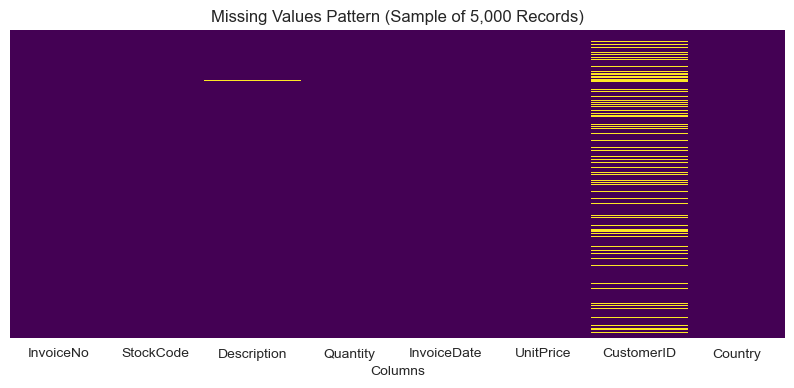

In [16]:
# Calculate missing value counts and percentages per column
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage (%)": missing_pct
})
display(missing_summary)

# Visualise missing values pattern on a random sample of 5,000 rows for fast rendering
plt.figure(figsize=(10, 4))
sns.heatmap(df.sample(5000, random_state=42).isnull(), yticklabels=False, cbar=False, cmap="viridis")
plt.title("Missing Values Pattern (Sample of 5,000 Records)")
plt.xlabel("Columns")
plt.show()

#### 3.1.2 Exact Duplicate Records
Exact duplicates across all eight columns can distort order counts and total revenue if left untreated.

In [18]:
# Count exact duplicate rows across all columns
duplicate_count = df.duplicated().sum()
duplicate_pct = round((duplicate_count / len(df)) * 100, 2)

print(f"Exact duplicate rows: {duplicate_count:,} ({duplicate_pct}%)")

# Display a sample of duplicated records
df[df.duplicated(keep=False)].sort_values(by=["InvoiceNo", "StockCode"]).head(10)

Exact duplicate rows: 5,268 (0.97%)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


#### 3.1.3 Cancelled Transactions and Non-Positive Quantities
In this dataset, invoice numbers starting with `'C'` indicate cancelled transactions. We inspect both cancelled invoices and any non-cancelled rows with zero or negative quantities.

In [20]:
# Identify cancelled invoices (InvoiceNo starting with 'C')
is_cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
cancelled_df = df[is_cancelled]

# Summarise cancellations and non-positive quantities
print(f"Cancelled line items: {len(cancelled_df):,}")
print(f"Unique cancelled invoices: {cancelled_df['InvoiceNo'].nunique():,}")
print(f"Total rows with Quantity <= 0: {(df['Quantity'] <= 0).sum():,}")
print(f"Non-cancelled rows with Quantity <= 0: {((~is_cancelled) & (df['Quantity'] <= 0)).sum():,}")

# Preview sample cancelled transactions
cancelled_df.head()

Cancelled line items: 9,288
Unique cancelled invoices: 3,836
Total rows with Quantity <= 0: 10,624
Non-cancelled rows with Quantity <= 0: 1,336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


#### 3.1.4 Invalid Unit Prices and Non-Standard Stock Codes
Next, we examine records with negative or zero unit prices, as well as non-standard stock codes that do not start with a digit. These entries are inspected first without automatically assuming they are invalid, as they may represent postage charges, discounts, service fees, or accounting adjustments.

In [22]:
# Inspect negative and zero unit prices
neg_price_df = df[df["UnitPrice"] < 0]
zero_price_df = df[df["UnitPrice"] == 0]

print(f"Rows with negative UnitPrice: {len(neg_price_df):,}")
print(f"Rows with zero UnitPrice: {len(zero_price_df):,}")
display(neg_price_df)

# Inspect StockCodes that do not start with a digit (non-standard / administrative codes)
non_product_mask = ~df["StockCode"].astype(str).str[0].str.isdigit()
print(f"\nRows with non-standard StockCode: {non_product_mask.sum():,}")
print(df.loc[non_product_mask, "StockCode"].value_counts().head(15))

Rows with negative UnitPrice: 2
Rows with zero UnitPrice: 2,515


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



Rows with non-standard StockCode: 2,995
StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
DCGS0003           5
Name: count, dtype: int64


#### 3.1.5 Outlier Detection (1.5 × IQR Rule / Tukey's Fences & Extreme Orders)
Using the **1.5 × IQR rule (Tukey's fences)** (`Q1 - 1.5 * IQR` and `Q3 + 1.5 * IQR`) and boxplots, we examine the spread of `Quantity` and `UnitPrice` on positive records. We also compare the largest positive and negative quantities side by side to check whether extreme transactions represent legitimate bulk orders or cancelled orders.

Quantity: Q1=1.00, Q3=10.00, IQR=9.00, Lower Fence=-12.50, Upper Fence=23.50, Outliers=56,363
UnitPrice: Q1=1.25, Q3=4.13, IQR=2.88, Lower Fence=-3.07, Upper Fence=8.45, Outliers=37,999


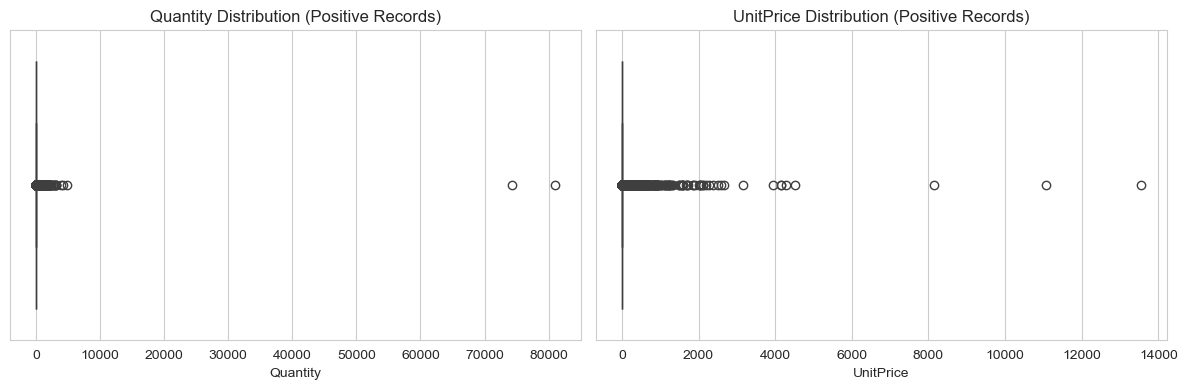

In [24]:
# Filter positive records only for outlier assessment
pos_df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Calculate IQR bounds and outlier counts
for col in ["Quantity", "UnitPrice"]:
    Q1 = pos_df[col].quantile(0.25)
    Q3 = pos_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = ((pos_df[col] < lower) | (pos_df[col] > upper)).sum()
    print(
        f"{col}: Q1={Q1:.2f}, Q3={Q3:.2f}, "
        f"IQR={IQR:.2f}, Lower Fence={lower:.2f}, "
        f"Upper Fence={upper:.2f}, Outliers={outlier_count:,}"
    )

# Plot boxplots to visualise extreme values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=pos_df["Quantity"], ax=axes[0])
axes[0].set_title("Quantity Distribution (Positive Records)")
sns.boxplot(x=pos_df["UnitPrice"], ax=axes[1])
axes[1].set_title("UnitPrice Distribution (Positive Records)")
plt.tight_layout()
plt.show()

In [25]:
# Compare the top 5 largest positive quantities against the top 5 largest negative quantities
cols_to_show = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID"]

print("Top 5 Largest Positive Quantities:")
display(df.sort_values(by="Quantity", ascending=False)[cols_to_show].head(5))

print("\nTop 5 Largest Negative Quantities (Returns / Cancellations):")
display(df.sort_values(by="Quantity", ascending=True)[cols_to_show].head(5))

Top 5 Largest Positive Quantities:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,16446.0
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,12346.0
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,2011-11-25 15:57:00,13256.0
74614,542504,37413,NaN,5568,0.00,2011-01-28 12:03:00,NaN
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,2011-10-27 12:26:00,12901.0



Top 5 Largest Negative Quantities (Returns / Cancellations):


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00,16446.0
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,2011-01-18 10:17:00,12346.0
225529,556690,23005,printing smudges/thrown away,-9600,0.00,2011-06-14 10:37:00,NaN
225530,556691,23005,printing smudges/thrown away,-9600,0.00,2011-06-14 10:37:00,NaN
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.03,2010-12-02 14:23:00,15838.0


#### 3.1.6 Data Quality Findings & Cleaning Strategy

The systematic data quality assessment identified several issues that require careful consideration before proceeding with data cleaning:

- **Missing Values:** The `CustomerID` column contains **135,080 missing values (24.93%)**, while `Description` contains **1,454 missing values (0.27%)**. Missing customer identifiers limit customer-level analysis, but these transactions can still contribute to overall sales analysis. Missing descriptions will require further investigation.
- **Duplicate Records:** A total of **5,268 exact duplicate rows** were identified, representing approximately **0.97%** of the dataset. These records may inflate transaction counts and revenue if retained without assessment; their removal will be performed during the cleaning stage.
- **Cancelled Transactions and Quantities:** The dataset contains **9,288 cancelled line items** across **3,836 unique cancelled invoices**. Additionally, **10,624 records** have non-positive quantities, including **1,336 records** without a cancellation invoice prefix (such as damaged or written-off stock). These records will be investigated separately before applying final filters.
- **Unit Prices and Stock Codes:** Two records contain negative unit prices (`-11,062.06`); both are described as `Adjust bad debt` under `StockCode` `B`, indicating accounting adjustments rather than ordinary product sales. A further **2,515 records** have zero unit prices, which may represent free items, damaged stock write-offs, or unpriced entries. The assessment also identified **2,995 records** with non-standard stock codes (`POST`, `DOT`, `M`, `C2`, `D`, etc.), which will be inspected by description and business purpose rather than automatically removed.
- **Outliers and Extreme Transactions:** The IQR method (`1.5 × IQR`) identified **56,363 statistical outliers** in `Quantity` (Upper Fence = `23.50`) and **37,999** in `UnitPrice` (Upper Fence = `8.45`) among positive records. Because this is a wholesale business, statistical outliers are not automatically treated as errors.
- **Reversed Extreme Orders:** Two exceptionally large transactions were verified directly against the cancellation records:
  - Invoice `581483` (`Quantity = +80,995`, `UnitPrice = £2.08`) was followed **12 minutes later** by cancellation `C581484` (`Quantity = -80,995`) for the exact same product, customer, and price.
  - Invoice `541431` (`Quantity = +74,215`, `UnitPrice = £1.04`) was followed **16 minutes later** by cancellation `C541433` (`Quantity = -74,215`) for the exact same product, customer, and price.
  - These matching records provide strong evidence that both extreme transactions were reversed and should not inflate cleaned product sales.

**Proposed Cleaning Strategy (keeping the original `df` intact and creating a cleaned DataFrame `df_clean`):**
1. Remove exact duplicate records (`drop_duplicates(keep='first')`) after confirming their impact.
2. Exclude cancelled transactions (`InvoiceNo` starting with `'C'`) and the two confirmed reversed extreme invoices (`581483`, `541431`) from the main product sales analysis, while keeping `df` intact for audit and cancellation analysis.
3. Inspect and handle non-positive quantities without a `'C'` prefix and zero-price transactions based on their descriptions.
4. Inspect non-standard `StockCode` entries (`POST`, `DOT`, `M`, `B`, `D`, etc.) and separate accounting adjustments / non-product fees from physical product sales where appropriate.
5. Retain missing `CustomerID` records in `df_clean` for overall revenue analysis, and filter `notnull()` only for customer-level analyses.
6. Preserve legitimate wholesale high-volume orders, combining business context with statistical checks (as covered in Week 7).

No records have been removed or modified during this assessment. The proposed actions will be implemented and validated step by step in **Section 3.2: Data Cleaning**.

### 3.2 Data Cleaning Pipeline

Before applying the cleaning steps, we briefly inspect the specific edge cases flagged in Section 3.1 (non-cancelled negative quantities, zero-price records, and non-standard stock codes) to verify their business meaning. We then keep the original `df` intact and build a cleaned DataFrame (`df_clean`) step by step, logging the exact number of rows affected at each stage.

#### 3.2.1 Inspecting Edge Cases Before Cleaning
We check the descriptions and prices of non-cancelled rows with `Quantity <= 0`, zero-price transactions, and the most frequent non-standard `StockCode` values.

In [29]:
# 1. Inspect non-cancelled rows with Quantity <= 0
non_cancel_neg = df[(~df["InvoiceNo"].astype(str).str.startswith("C")) & (df["Quantity"] <= 0)]
print("Non-cancelled rows with Quantity <= 0:", len(non_cancel_neg))
print("Unique UnitPrice values in these rows:", non_cancel_neg["UnitPrice"].unique())
print("Top descriptions:")
print(non_cancel_neg["Description"].value_counts(dropna=False).head(8))

# 2. Inspect zero-price rows
zero_price = df[df["UnitPrice"] == 0]
print("\nZero-price rows top descriptions:")
print(zero_price["Description"].value_counts(dropna=False).head(8))

# 3. Inspect descriptions of the most frequent non-standard StockCodes
non_std = df[~df["StockCode"].astype(str).str[0].str.isdigit()]
print("\nTop non-standard StockCodes and their descriptions:")
print(non_std.groupby(["StockCode", "Description"]).size().sort_values(ascending=False).head(12))

Non-cancelled rows with Quantity <= 0: 1336
Unique UnitPrice values in these rows: [0.]
Top descriptions:
Description
NaN                      862
check                    120
damages                   45
damaged                   42
?                         41
sold as set on dotcom     20
Damaged                   14
thrown away                9
Name: count, dtype: int64

Zero-price rows top descriptions:
Description
NaN                      1454
check                     159
?                          47
damages                    45
damaged                    43
found                      25
sold as set on dotcom      20
adjustment                 16
Name: count, dtype: int64

Top non-standard StockCodes and their descriptions:
StockCode     Description                       
POST          POSTAGE                               1252
DOT           DOTCOM POSTAGE                         709
M             Manual                                 571
C2            CARRIAGE                

#### 3.2.2 Applying the Cleaning Steps
Using a copy of the raw dataset (`df_clean`), we apply each cleaning rule transparently and track the number of rows removed:
1. **Remove exact duplicates** (`drop_duplicates(keep='first')`) to prevent double-counting.
2. **Remove cancelled invoices** (`InvoiceNo` starting with `'C'`) from the cleaned product sales dataset.
3. **Remove confirmed reversed extreme invoices** (`581483` and `541431`), which were cancelled minutes later for identical quantities and prices.
4. **Keep positive quantities and positive unit prices** (`Quantity > 0` and `UnitPrice > 0`), excluding warehouse write-offs, zero-price adjustments, and bad-debt entries.
5. **Remove administrative / non-product stock codes** (`POST`, `DOT`, `M`, `C2`, `BANK CHARGES`, `AMAZONFEE`, `D`, `B`, `S`, `CRUK`) so product and revenue visualisations reflect physical gift sales.
6. **Clean text formatting and preserve missing `CustomerID`s:** strip extra whitespace from `Description` and keep rows with missing `CustomerID` for overall sales reporting (these will be excluded only in customer-specific analyses).

In [31]:
# Start from a copy so the original DataFrame (df) remains intact
df_clean = df.copy()
print(f"Starting rows (raw df):              {len(df_clean):,}")

# Step 1: Remove exact duplicate rows
before = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first")
print(f"After removing exact duplicates:     {len(df_clean):,} (removed {before - len(df_clean):,})")

# Step 2: Remove cancelled invoices (InvoiceNo starting with 'C')
before = len(df_clean)
df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).str.startswith("C")]
print(f"After removing cancelled invoices:   {len(df_clean):,} (removed {before - len(df_clean):,})")

# Step 3: Remove the two confirmed reversed extreme orders (581483 and 541431)
before = len(df_clean)
reversed_invoices = ["581483", "541431"]
df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).isin(reversed_invoices)]
print(f"After removing reversed extremes:    {len(df_clean):,} (removed {before - len(df_clean):,})")

# Step 4: Keep only positive quantities and positive unit prices
before = len(df_clean)
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["UnitPrice"] > 0)]
print(f"After filtering Quantity/Price > 0:  {len(df_clean):,} (removed {before - len(df_clean):,})")

# Step 5: Remove non-product / administrative StockCodes
before = len(df_clean)
admin_codes = ["POST", "DOT", "M", "C2", "BANK CHARGES", "AMAZONFEE", "D", "B", "S", "CRUK"]
df_clean = df_clean[~df_clean["StockCode"].astype(str).isin(admin_codes)]
print(f"After removing non-product codes:    {len(df_clean):,} (removed {before - len(df_clean):,})")

# Step 6: Clean product descriptions and reset index
df_clean["Description"] = df_clean["Description"].str.strip()
df_clean = df_clean.reset_index(drop=True)

retained_pct = (len(df_clean) / len(df)) * 100
print(f"\nFinal cleaned dataset: {len(df_clean):,} rows ({retained_pct:.2f}% of raw data retained)")

Starting rows (raw df):              541,909
After removing exact duplicates:     536,641 (removed 5,268)
After removing cancelled invoices:   527,390 (removed 9,251)
After removing reversed extremes:    527,388 (removed 2)
After filtering Quantity/Price > 0:  524,876 (removed 2,512)
After removing non-product codes:    522,570 (removed 2,306)

Final cleaned dataset: 522,570 rows (96.43% of raw data retained)


#### 3.2.3 Post-Cleaning Validation (Before vs. After)
We validate the cleaned dataset by comparing key structural and statistical checks against the raw DataFrame.

In [33]:
# Compare key metrics before and after cleaning
comparison = pd.DataFrame({
    "Raw Dataset (df)": [
        len(df),
        df["InvoiceNo"].nunique(),
        df.duplicated().sum(),
        df["Description"].isnull().sum(),
        df["CustomerID"].isnull().sum(),
        df["Quantity"].min(),
        df["Quantity"].max(),
        df["UnitPrice"].min(),
        df["UnitPrice"].max()
    ],
    "Cleaned Dataset (df_clean)": [
        len(df_clean),
        df_clean["InvoiceNo"].nunique(),
        df_clean.duplicated().sum(),
        df_clean["Description"].isnull().sum(),
        df_clean["CustomerID"].isnull().sum(),
        df_clean["Quantity"].min(),
        df_clean["Quantity"].max(),
        df_clean["UnitPrice"].min(),
        df_clean["UnitPrice"].max()
    ]
}, index=[
    "Total Rows",
    "Unique Invoices",
    "Exact Duplicates",
    "Missing Descriptions",
    "Missing CustomerIDs",
    "Min Quantity",
    "Max Quantity",
    "Min UnitPrice",
    "Max UnitPrice"
])

display(comparison)

# Descriptive statistics of the cleaned dataset
df_clean.describe()


,Raw Dataset (df),Cleaned Dataset (df_clean)
Total Rows,541909.00,522570.000
Unique Invoices,25900.00,19771.000
Exact Duplicates,5268.00,0.000
Missing Descriptions,1454.00,0.000
Missing CustomerIDs,135080.00,131419.000
Min Quantity,-80995.00,1.000
Max Quantity,80995.00,4800.000
Min UnitPrice,-11062.06,0.001
Max UnitPrice,38970.00,649.500


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,522570.000000,522570,522570.000000,391151.000000
mean,10.345429,2011-07-04 16:40:12.073598208,3.275054,15295.175753
min,1.000000,2010-12-01 08:26:00,0.001000,12347.000000
25%,1.000000,2011-03-28 12:13:00,1.250000,13969.000000
50%,4.000000,2011-07-20 11:55:00,2.080000,15159.000000
75%,12.000000,2011-10-19 11:44:00,4.130000,16794.000000
max,4800.000000,2011-12-09 12:50:00,649.500000,18287.000000
std,37.852897,NaN,4.396064,1710.331391


#### 3.2.4 Cleaning Summary and Justification

The cleaning process reduced the original dataset from **541,909** to **522,570** records, retaining **96.43%** of the original rows.

The main cleaning decisions were:
- **Duplicates:** Removed **5,268** exact duplicate records to prevent double-counting.
- **Cancelled transactions:** Excluded **9,251** cancelled invoice line items (`InvoiceNo` starting with `'C'`) from the main sales analysis. *(Note: the initial audit found 9,288 cancelled rows because 37 of them were exact duplicates already removed in Step 1.)*
- **Reversed extreme orders:** Removed two exceptionally large invoices (`581483` and `541431`, worth £245,653.20 combined) that had matching cancellation invoices minutes later, while preserving other legitimate high-volume orders.
- **Invalid quantities and prices:** Excluded **2,512** remaining records with zero or negative quantities or unit prices, as they represent stock write-offs, unpriced items, or bad-debt adjustments rather than valid sales.
- **Administrative codes:** Removed **2,306** records (`POST`, `DOT`, `M`, `C2`, `BANK CHARGES`, `AMAZONFEE`, `D`, `B`, `S`, `CRUK`) based on their non-product business meaning (postage, manual charges, discounts, samples, and bank fees). Other alphanumeric codes representing actual gift items were retained.
- **Missing values:** Retained **131,419** records with missing `CustomerID` values (**25.15%** of `df_clean`) for overall sales reporting, excluding them only in customer-level analysis. Missing descriptions were naturally excluded alongside invalid quantity/price records rather than filled artificially.

The original DataFrame (`df`) was kept intact while all cleaning steps were applied to `df_clean`, allowing direct comparison before and after cleaning. Because discounts, postage, and cancellations are excluded, the revenue calculated from `df_clean` represents **cleaned product sales revenue** rather than a full accounting net revenue figure.

## 4. Feature Engineering

### 4.1 Creating Business-Relevant Derived Variables

To answer management's questions effectively during Exploratory Data Analysis (Section 5) and power the interactive dashboard (Section 6), we create six derived variables in `df_clean`:

- **`Revenue`**: Line-item monetary value (`Quantity × UnitPrice`, in GBP).
- **`YearMonth`**: Year and month label (`YYYY-MM`) for monthly sales trend analysis.
- **`DayOfWeek`**: Day name (`Monday` to `Sunday`) to identify weekly ordering patterns.
- **`Hour`**: Hour of the day (`0` to `23`) to examine operational peak hours.
- **`Market`**: Classifies each record into **`United Kingdom`** (domestic) or **`International`** using `np.where()`, allowing clear comparison without UK dominance hiding overseas trends.
- **`InvoiceValue`**: Total monetary value of each complete order (`InvoiceNo`), computed via `groupby()` and merged back into `df_clean`. This enables both order-value distribution analysis and minimum-order-value filtering in the dashboard.

In [36]:
# Calculate line-item revenue
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Extract temporal features from InvoiceDate
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.strftime("%Y-%m")
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

# Classify transactions into United Kingdom vs International markets
df_clean["Market"] = np.where(df_clean["Country"] == "United Kingdom", "United Kingdom", "International")

# Calculate total value per invoice and merge back into df_clean
if "InvoiceValue" in df_clean.columns:
    df_clean = df_clean.drop(columns=["InvoiceValue"])

invoice_totals = df_clean.groupby("InvoiceNo")["Revenue"].sum().reset_index()
invoice_totals = invoice_totals.rename(columns={"Revenue": "InvoiceValue"})
df_clean = pd.merge(df_clean, invoice_totals, on="InvoiceNo", how="left")

# Preview the engineered features
df_clean[["InvoiceNo", "Quantity", "UnitPrice", "Revenue", "InvoiceValue", "YearMonth", "DayOfWeek", "Hour", "Market"]].head()

,InvoiceNo,Quantity,UnitPrice,Revenue,InvoiceValue,YearMonth,DayOfWeek,Hour,Market
0,536365,6,2.55,15.30,139.12,2010-12,Wednesday,8,United Kingdom
1,536365,6,3.39,20.34,139.12,2010-12,Wednesday,8,United Kingdom
2,536365,8,2.75,22.00,139.12,2010-12,Wednesday,8,United Kingdom
3,536365,6,3.39,20.34,139.12,2010-12,Wednesday,8,United Kingdom
4,536365,6,3.39,20.34,139.12,2010-12,Wednesday,8,United Kingdom


### 4.2 Feature Validation and Summary Metrics
We verify that the new columns contain no missing values and inspect the overall revenue, order value benchmarks (mean vs. median), and domestic versus international market share.

In [38]:
# Check updated dimensions and confirm zero missing values in engineered features
new_cols = ["Revenue", "YearMonth", "DayOfWeek", "Hour", "Market", "InvoiceValue"]
print("Updated shape:", df_clean.shape)
print("\nMissing values in new features:")
print(df_clean[new_cols].isnull().sum())

# Summarise overall revenue and order-level statistics
order_values = df_clean.groupby("InvoiceNo")["Revenue"].sum()
print(f"\nTotal Cleaned Sales Revenue: £{df_clean['Revenue'].sum():,.2f}")
print(f"Total Unique Orders:  {df_clean['InvoiceNo'].nunique():,}")
print(f"Mean Order Value:     £{order_values.mean():,.2f}")
print(f"Median Order Value:   £{order_values.median():,.2f}")
print(f"Max Order Value:      £{order_values.max():,.2f}")

# Calculate revenue share by Market
market_summary = df_clean.groupby("Market")["Revenue"].sum().reset_index()
market_summary["Revenue_Share (%)"] = (market_summary["Revenue"] / market_summary["Revenue"].sum() * 100).round(2)
display(market_summary)

Updated shape: (522570, 14)

Missing values in new features:
Revenue         0
YearMonth       0
DayOfWeek       0
Hour            0
Market          0
InvoiceValue    0
dtype: int64

Total Cleaned Sales Revenue: £10,002,254.48
Total Unique Orders:  19,771
Mean Order Value:     £505.91
Median Order Value:   £302.20
Max Order Value:      £52,940.94


,Market,Revenue,Revenue_Share (%)
0,International,1522775.650,15.22
1,United Kingdom,8479478.833,84.78


### 4.3 Feature Engineering Summary

The feature engineering process successfully created six additional variables, increasing the cleaned dataset from **8 to 14 columns** while retaining all **522,570 records**.

The new variables provide useful business context for the next stages of the analysis:
- **`Revenue`** calculates the monetary value of each transaction line (`Quantity × UnitPrice`).
- **`YearMonth`**, **`DayOfWeek`** and **`Hour`** support the analysis of monthly, weekly and hourly sales patterns.
- **`Market`** separates domestic sales (`United Kingdom`) from `International` sales.
- **`InvoiceValue`** calculates the total cleaned product value of each invoice, supporting order-level analysis and dashboard filtering.

Validation confirmed that all six new variables contain **zero missing values**.

The cleaned dataset records total cleaned product sales revenue of **£10,002,254.48** across **19,771 unique orders**. The mean order value is **£505.91**, whereas the median is **£302.20** (maximum **£52,940.94**). This gap confirms that high-value wholesale orders pull the mean upward, making the median an essential complementary benchmark for a typical order.

Geographically, the **United Kingdom accounts for 84.78%** of cleaned sales revenue (£8,479,478.83), while **international markets contribute 15.22%** (£1,522,775.65). Separating these markets prevents UK volume from obscuring international trends.

Overall, these derived variables establish a clean analytical foundation for the Exploratory Data Analysis (Section 5) and interactive dashboard (Section 6).

## 5. Exploratory Data Analysis (Static Visualisations)

Using the cleaned dataset (`df_clean`) and engineered features, this section explores business performance through static visualisations built with `Matplotlib` and `Seaborn`. Following the structure taught in class, each visualisation is accompanied by its analytical **objective**, a justification for **why the chart type is appropriate**, and the **key insights** derived from the data.

### 5.1 Visualisation 1: Monthly Cleaned Sales Revenue Trend
We aggregate cleaned sales revenue and order counts by month (`YearMonth`) and include a 3-month moving average (`rolling(window=3).mean()`) alongside month-on-month percentage changes (`pct_change()`). Note that **December 2011 (`2011-12`) is incomplete**, containing only the first nine days of the month.

,Revenue,Orders,Rolling_3M,MoM_Change (%)
YearMonth,,,,
2010-12,775717.500,1550,NaN,NaN
2011-01,593255.860,1080,NaN,-23.52
2011-02,507866.540,1093,6.256133e+05,-14.39
2011-03,689841.840,1440,5.969881e+05,35.83
2011-04,515469.661,1235,5.710593e+05,-25.28
2011-05,740036.330,1668,6.484493e+05,43.57
2011-06,737683.990,1525,6.643967e+05,-0.32
2011-07,688252.671,1452,7.219910e+05,-6.70
2011-08,724308.160,1339,7.167483e+05,5.24


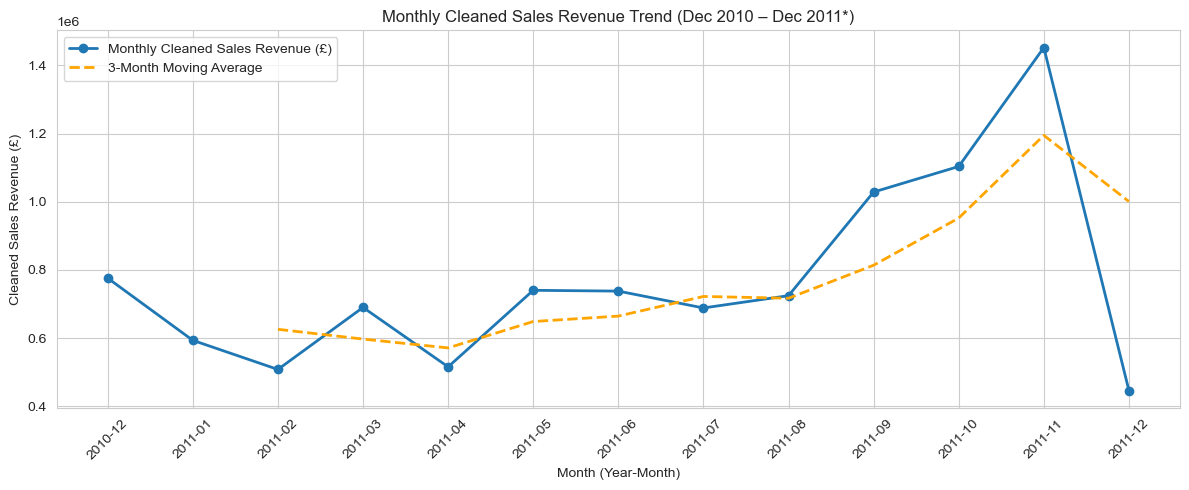

In [42]:
# Aggregate monthly cleaned sales revenue and unique order counts
monthly_revenue = df_clean.groupby("YearMonth")["Revenue"].sum()
monthly_orders = df_clean.groupby("YearMonth")["InvoiceNo"].nunique()

monthly_sales = pd.DataFrame({
    "Revenue": monthly_revenue,
    "Orders": monthly_orders
})

# Calculate 3-month moving average and month-on-month percentage change
monthly_sales["Rolling_3M"] = monthly_sales["Revenue"].rolling(window=3).mean()
monthly_sales["MoM_Change (%)"] = (monthly_sales["Revenue"].pct_change() * 100).round(2)

display(monthly_sales)

# Plot monthly revenue trend alongside the 3-month moving average
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales["Revenue"], marker="o", linewidth=2, label="Monthly Cleaned Sales Revenue (£)")
plt.plot(monthly_sales.index, monthly_sales["Rolling_3M"], linestyle="--", linewidth=2, color="orange", label="3-Month Moving Average")
plt.title("Monthly Cleaned Sales Revenue Trend (Dec 2010 – Dec 2011*)")
plt.xlabel("Month (Year-Month)")
plt.ylabel("Cleaned Sales Revenue (£)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

- **Objective:** To identify monthly cleaned sales revenue trends and changes in order activity across the reporting period.
- **Why this plot:** A line chart is well suited to time-series data because it shows continuous movement over time. Adding a 3-month moving average smooths short-term fluctuations to reveal the broader direction, while month-on-month percentage changes highlight sharp increases or decreases.
- **Learning / Insights:** **November 2011** recorded the highest monthly cleaned sales revenue at **£1,452,115.98** across **2,751 unique orders**. Sales increased noticeably from September onwards, rising **41.98%** in September and a further **31.61%** in November. While this indicates a strong **observed pre-Christmas sales increase** in 2011, the dataset covers only one annual cycle, so it cannot confirm recurring multi-year seasonality on its own. Additionally, **December 2011** includes data only up to **9 December** (£446,029.65 across 815 orders) and should not be compared directly with full months.

### 5.2 Visualisation 2: Operational Pattern (Revenue by Day of Week and Hour)
To understand when customers place orders during the week, we aggregate cleaned sales revenue across `DayOfWeek` and `Hour` and display the pattern as a heatmap.

Revenue by Day of Week (£):
DayOfWeek
Monday       1683019.56
Tuesday      2007934.27
Wednesday    1782465.88
Thursday     2131755.60
Friday       1598767.67
Saturday           0.00
Sunday        798311.50
Name: Revenue, dtype: float64

Top 5 Hours by Revenue (£):
Hour
12    1412921.32
10    1324607.80
15    1274034.20
13    1220426.07
11    1196812.55
Name: Revenue, dtype: float64


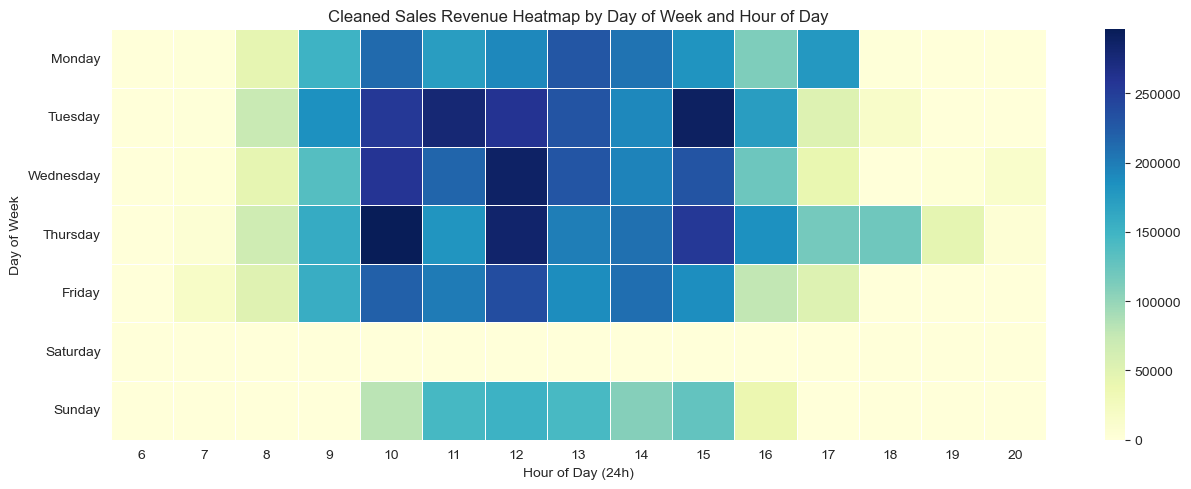

In [45]:
# Define logical weekday order from Monday to Sunday
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Create a Day-of-Week by Hour revenue matrix
day_hour_revenue = pd.pivot_table(
    df_clean,
    values="Revenue",
    index="DayOfWeek",
    columns="Hour",
    aggfunc="sum",
    fill_value=0
).reindex(day_order, fill_value=0)

# Print revenue summary by weekday and top 5 hours
print("Revenue by Day of Week (£):")
print(df_clean.groupby("DayOfWeek")["Revenue"].sum().reindex(day_order, fill_value=0).round(2))

print("\nTop 5 Hours by Revenue (£):")
print(df_clean.groupby("Hour")["Revenue"].sum().sort_values(ascending=False).head(5).round(2))

# Plot heatmap of cleaned sales revenue by day of week and hour
plt.figure(figsize=(13, 5))
sns.heatmap(day_hour_revenue, cmap="YlGnBu", linewidths=0.5)
plt.title("Cleaned Sales Revenue Heatmap by Day of Week and Hour of Day")
plt.xlabel("Hour of Day (24h)")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()

- **Objective:** To identify which days of the week and hours of the day generate the highest cleaned sales revenue.
- **Why this plot:** A heatmap displays two dimensions simultaneously (`DayOfWeek` and `Hour`), using colour intensity to highlight peak trading periods and quieter windows clearly.
- **Learning / Insights:** **Thursday** recorded the highest cumulative revenue (**£2,131,755.60**), followed by **Tuesday** (**£2,007,934.27**). **Saturday** has **no recorded transactions** in the cleaned dataset (£0.00), whereas **Sunday** accounts for **£798,311.50** (2,203 orders). Because the 12-month period contains slightly different numbers of observed calendar days per weekday (e.g., 47 Mondays vs. 53 Thursdays), the verification table below calculates both **cumulative totals** and **average revenue per observed day** to ensure a fair comparison. By hour, **12:00** generated the highest total (**£1,412,921.32**), followed by **10:00**, **15:00**, **13:00**, and **11:00**.

In [47]:
# Count distinct observed calendar dates per day of week to compare totals and daily averages
df_clean["InvoiceDay"] = df_clean["InvoiceDate"].dt.date
observed_days = df_clean.groupby("DayOfWeek")["InvoiceDay"].nunique()
weekday_revenue = df_clean.groupby("DayOfWeek")["Revenue"].sum()

weekday_check = pd.DataFrame({
    "Observed_Days": observed_days,
    "Orders": df_clean.groupby("DayOfWeek")["InvoiceNo"].nunique(),
    "Records": df_clean.groupby("DayOfWeek")["InvoiceNo"].count(),
    "Total_Revenue (£)": weekday_revenue.round(2),
    "Avg_Daily_Revenue (£)": (weekday_revenue / observed_days).round(2)
}).reindex(day_order, fill_value=0)

# Remove temporary helper column so df_clean retains its 14 core columns
df_clean = df_clean.drop(columns=["InvoiceDay"])

# Mark the average as unavailable when no days were observed
weekday_check.loc[weekday_check["Observed_Days"] == 0, "Avg_Daily_Revenue (£)"] = np.nan

display(weekday_check)

,Observed_Days,Orders,Records,Total_Revenue (£),Avg_Daily_Revenue (£)
DayOfWeek,,,,,
Monday,47,3076,92038,1683019.56,35808.93
Tuesday,52,3508,98251,2007934.27,38614.12
Wednesday,53,3667,91072,1782465.88,33631.43
Thursday,53,4209,99765,2131755.60,40221.80
Friday,50,3108,79235,1598767.67,31975.35
Saturday,0,0,0,0.00,NaN
Sunday,50,2203,62209,798311.50,15966.23


### 5.3 Visualisation 3: Product Performance Analysis
To compare which products drive the largest share of cleaned sales revenue versus unit volume, we aggregate revenue, total quantity sold, and order counts by `Description` and visualise the top 10 products by revenue.

Total unique products: 4,007
Top 10 products combined revenue share: 8.03%


,Description,Revenue,Quantity,Orders,Revenue_Share (%)
2835,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,1.74
3825,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872,2256,1.06
2397,PARTY BUNTING,99445.23,18283,1685,0.99
1800,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,0.94
2722,RABBIT NIGHT LIGHT,66870.03,30739,994,0.67
2367,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160,0.65
216,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455,0.59
733,CHILLI LIGHTS,54096.36,10302,661,0.54
3442,SPOTTY BUNTING,42513.48,8320,1140,0.43
1798,JUMBO BAG PINK POLKADOT,42401.01,21448,1218,0.42



Top 5 Products by Unit Volume (Quantity):


,Description,Quantity,Revenue,Orders
3915,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,535
1800,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
3825,WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72,2256
2663,POPCORN HOLDER,36749,34288.67,803
2323,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,1320


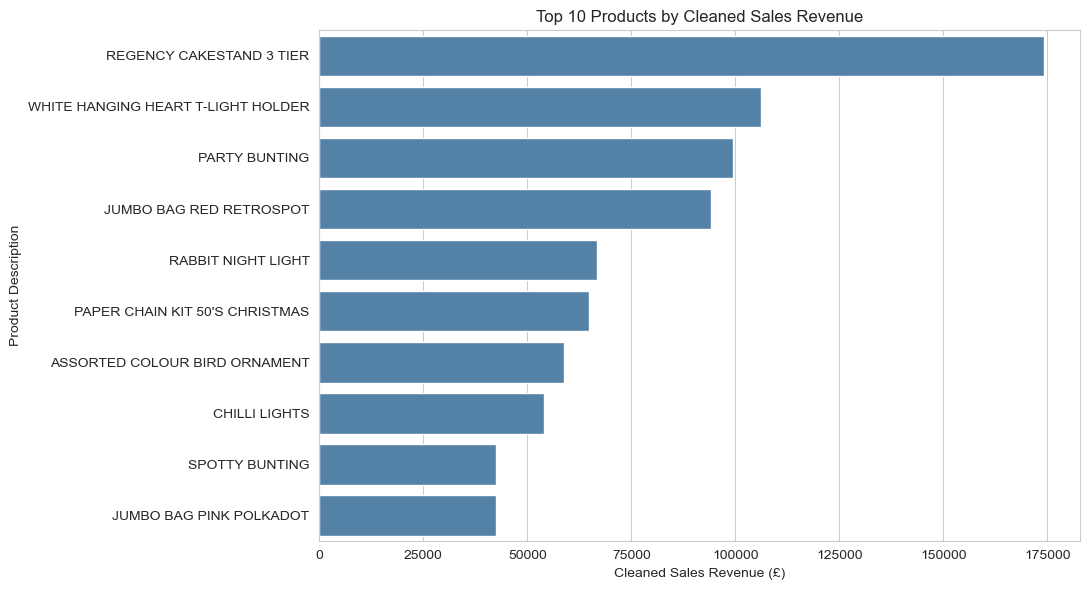

In [49]:
# Aggregate revenue, quantity sold, and order count by product description
product_summary = pd.DataFrame({
    "Revenue": df_clean.groupby("Description")["Revenue"].sum(),
    "Quantity": df_clean.groupby("Description")["Quantity"].sum(),
    "Orders": df_clean.groupby("Description")["InvoiceNo"].nunique()
}).reset_index()

# Calculate each product percentage share of total cleaned sales revenue
total_cleaned_sales_revenue = df_clean["Revenue"].sum()
product_summary["Revenue_Share (%)"] = (product_summary["Revenue"] / total_cleaned_sales_revenue * 100).round(2)

# Extract top 10 products by revenue and top 5 by quantity
top10_products = product_summary.sort_values(by="Revenue", ascending=False).head(10)
top5_volume = product_summary.sort_values(by="Quantity", ascending=False).head(5)

print(f"Total unique products: {len(product_summary):,}")
print(f"Top 10 products combined revenue share: {top10_products['Revenue_Share (%)'].sum():.2f}%")
display(top10_products)

print("\nTop 5 Products by Unit Volume (Quantity):")
display(top5_volume[["Description", "Quantity", "Revenue", "Orders"]])

# Plot horizontal bar chart of Top 10 products by cleaned sales revenue
plt.figure(figsize=(11, 6))
sns.barplot(x="Revenue", y="Description", data=top10_products, color="steelblue")
plt.title("Top 10 Products by Cleaned Sales Revenue")
plt.xlabel("Cleaned Sales Revenue (£)")
plt.ylabel("Product Description")
plt.tight_layout()
plt.show()

- **Objective:** To identify the best-performing products based on both cleaned sales revenue and unit sales volume.
- **Why this plot:** A horizontal bar chart keeps long product descriptions readable without overlapping or rotated labels, while grouping by `Description` allows direct comparison of revenue, quantity sold, and order counts.
- **Learning / Insights:** Across **4,007 unique products**, **`REGENCY CAKESTAND 3 TIER`** generated the highest cleaned sales revenue at **£174,156.54** (1.74% of total revenue across 13,851 units). In contrast, **`WORLD WAR 2 GLIDERS ASSTD DESIGNS`** led unit volume with **54,951 units** sold (£13,814.01 in revenue). Together, the top 10 products by revenue represent **8.03%** of total cleaned sales revenue, showing that sales are spread across a wide range of products rather than concentrated in a few items. This confirms the value of tracking revenue and unit volume separately.

### 5.4 Visualisation 4: Regional Market Analysis (UK vs. International)
Because the United Kingdom accounts for most sales, plotting all 38 countries on a single axis compresses international markets into very small bars. Here we separate the **UK vs. International share** from the **Top 10 International Markets** for clearer comparison.

Total countries in cleaned dataset: 38
Top 10 international markets share of international revenue: 85.56%


,Country,Revenue,Orders,Quantity,Share_of_Intl (%)
24,Netherlands,283889.34,93,200258,18.64
10,EIRE,270850.86,282,146896,17.79
14,Germany,205381.15,443,118032,13.49
13,France,184493.00,382,111226,12.12
0,Australia,138103.81,56,83890,9.07
31,Spain,55706.56,88,27724,3.66
33,Switzerland,53065.60,50,30515,3.48
20,Japan,37416.37,19,26016,2.46
3,Belgium,36927.34,98,22962,2.43
32,Sweden,36828.83,34,36037,2.42


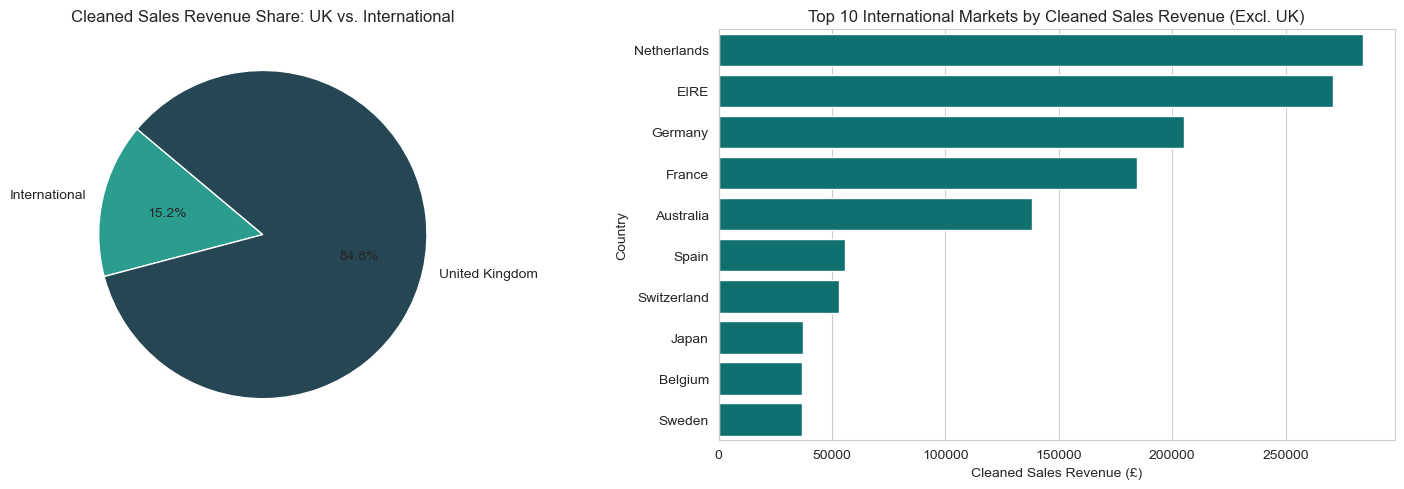

In [52]:
# Aggregate cleaned sales revenue by Market (UK vs International)
market_rev = df_clean.groupby("Market")["Revenue"].sum()

# Filter international sales and aggregate by Country
intl_df = df_clean[df_clean["Country"] != "United Kingdom"]
intl_summary = pd.DataFrame({
    "Revenue": intl_df.groupby("Country")["Revenue"].sum(),
    "Orders": intl_df.groupby("Country")["InvoiceNo"].nunique(),
    "Quantity": intl_df.groupby("Country")["Quantity"].sum()
}).reset_index()

intl_summary["Share_of_Intl (%)"] = (intl_summary["Revenue"] / intl_summary["Revenue"].sum() * 100).round(2)
top10_intl = intl_summary.sort_values(by="Revenue", ascending=False).head(10)

print(f"Total countries in cleaned dataset: {df_clean['Country'].nunique()}")
print(f"Top 10 international markets share of international revenue: {top10_intl['Share_of_Intl (%)'].sum():.2f}%")
display(top10_intl)

# Create a side-by-side comparison: UK vs International share and Top 10 International countries
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left chart: Pie chart for UK vs International revenue share
axes[0].pie(
    market_rev.values,
    labels=market_rev.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#2a9d8f", "#264653"]
)
axes[0].set_title("Cleaned Sales Revenue Share: UK vs. International")

# Right chart: Horizontal bar chart for Top 10 International markets
sns.barplot(x="Revenue", y="Country", data=top10_intl, color="teal", ax=axes[1])
axes[1].set_title("Top 10 International Markets by Cleaned Sales Revenue (Excl. UK)")
axes[1].set_xlabel("Cleaned Sales Revenue (£)")
axes[1].set_ylabel("Country")

plt.tight_layout()
plt.show()

- **Objective:** To compare the revenue contribution of the United Kingdom against international markets and identify the strongest overseas countries.
- **Why this plot:** A pie chart shows the whole-part split between the domestic UK market and international sales, while a side-by-side horizontal bar chart ranks the top 10 international markets cleanly without UK scale distortion.
- **Learning / Insights:** Across **38 countries**, the **United Kingdom** generates **84.78%** of cleaned sales revenue (£8,479,478.83), while **international markets** contribute **15.22%** (£1,522,775.65). Among international markets, the **Netherlands** leads (**£283,889.34**, 18.64%), followed closely by **EIRE** (Ireland, **£270,850.86**, 17.79%), **Germany** (**£205,381.15**, 13.49%), **France** (**£184,493.00**, 12.12%), and **Australia** (**£138,103.81**, 9.07%). The top four European markets alone account for **62.04%** of international revenue, and the **top 10 represent 85.56%**, highlighting strong concentration in a small group of key overseas markets.

### 5.5 Visualisation 5: Order Value Distribution
To understand what a typical order looks like, we aggregate cleaned sales revenue at the invoice level (`InvoiceNo`) and plot a histogram and boxplot. Because large wholesale orders reach up to £52,940.94, the charts display orders up to the **95th percentile** (£1,506.93) for readability, while the printed statistics and Mean/Median reference lines reflect **all 19,771 orders**.

Total unique orders:          19,771
Mean Order Value:             £505.91
Median Order Value:           £302.20
95th Percentile Order Value:  £1,506.93
Maximum Order Value:          £52,940.94
Orders above 95th percentile: 989


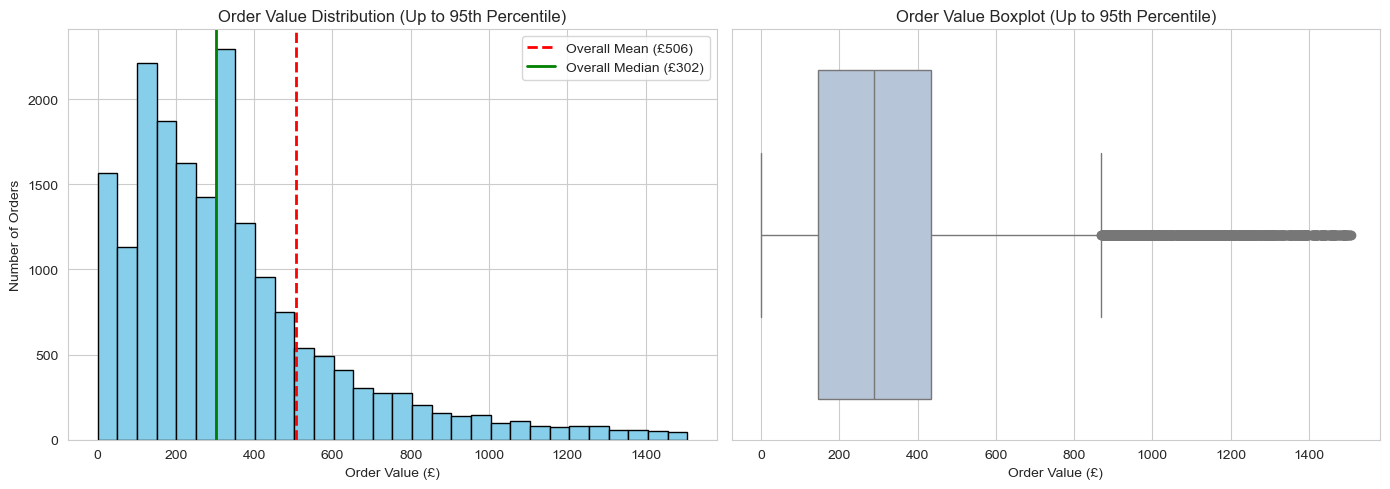

In [55]:
# Aggregate total cleaned sales revenue per unique invoice (order level)
order_values = df_clean.groupby("InvoiceNo")["Revenue"].sum()

# Calculate summary statistics across all orders
mean_val = order_values.mean()
median_val = order_values.median()
p95_val = order_values.quantile(0.95)

print(f"Total unique orders:          {len(order_values):,}")
print(f"Mean Order Value:             £{mean_val:,.2f}")
print(f"Median Order Value:           £{median_val:,.2f}")
print(f"95th Percentile Order Value:  £{p95_val:,.2f}")
print(f"Maximum Order Value:          £{order_values.max():,.2f}")
print(f"Orders above 95th percentile: {(order_values > p95_val).sum():,}")

# Subset orders up to the 95th percentile for clear visual inspection
typical_orders = order_values[order_values <= p95_val]

# Create side-by-side Histogram and Boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left chart: Histogram with overall mean and median reference lines
axes[0].hist(typical_orders, bins=30, color="skyblue", edgecolor="black")
axes[0].axvline(mean_val, color="red", linestyle="--", linewidth=2, label=f"Overall Mean (£{mean_val:.0f})")
axes[0].axvline(median_val, color="green", linestyle="-", linewidth=2, label=f"Overall Median (£{median_val:.0f})")
axes[0].set_title("Order Value Distribution (Up to 95th Percentile)")
axes[0].set_xlabel("Order Value (£)")
axes[0].set_ylabel("Number of Orders")
axes[0].legend()

# Right chart: Boxplot showing spread and outliers
sns.boxplot(x=typical_orders, color="lightsteelblue", ax=axes[1])
axes[1].set_title("Order Value Boxplot (Up to 95th Percentile)")
axes[1].set_xlabel("Order Value (£)")

plt.tight_layout()
plt.show()

- **Objective:** To examine the distribution of order values (`InvoiceValue`) and compare typical orders with high-value transactions.
- **Why this plot:** A histogram shows the frequency distribution and right skewness of order values, while a boxplot summarises spread, quartiles, and upper outliers. Limiting the plotted x-axis to the 95th percentile keeps the main distribution readable, while the overall mean and median lines preserve full-dataset benchmarks.
- **Learning / Insights:** Across **19,771 unique orders**, the **overall mean order value (£505.91)** is considerably higher than the **overall median (£302.20)**, confirming a strongly right-skewed distribution pulled upward by large orders. The **95th percentile is £1,506.93**, with **989 orders** (5%) exceeding this threshold up to **£52,940.94**. Consequently, the median is an important complementary measure when describing a typical order.

### 5.6 Visualisation 6: Repeat Purchasing Behaviour and Customer Revenue Concentration
Prior research on this retail dataset highlights the importance of analysing customer purchase frequency and monetary spend (Chen, Sain and Guo, 2012). Consistent with our cleaning strategy in Section 3, records with missing `CustomerID` values are excluded **only** for this customer-level analysis (`notnull()`). We examine the relationship between order frequency and total customer spend, coloured by `Market`, and calculate repeat purchasing and top-20% revenue concentration.

Total identifiable customers:        4,333
Identified customer revenue:         £8,491,574.44
Repeat customers (> 1 order):        65.27%
Top 20% customers (866) revenue share: 73.89%

Top 10 Customers by Total Revenue:


,CustomerID,Orders,Total_Revenue,Market,Avg_Order_Value
1688,14646.0,72,279138.02,International,3876.92
4196,18102.0,60,259657.30,United Kingdom,4327.62
3724,17450.0,46,194390.79,United Kingdom,4225.89
1878,14911.0,198,136161.83,International,687.69
54,12415.0,20,124564.53,International,6228.23
1332,14156.0,54,116560.08,International,2158.52
3767,17511.0,31,91062.38,United Kingdom,2937.50
2699,16029.0,62,72708.09,United Kingdom,1172.71
3173,16684.0,28,66653.56,United Kingdom,2380.48
995,13694.0,50,65039.62,United Kingdom,1300.79


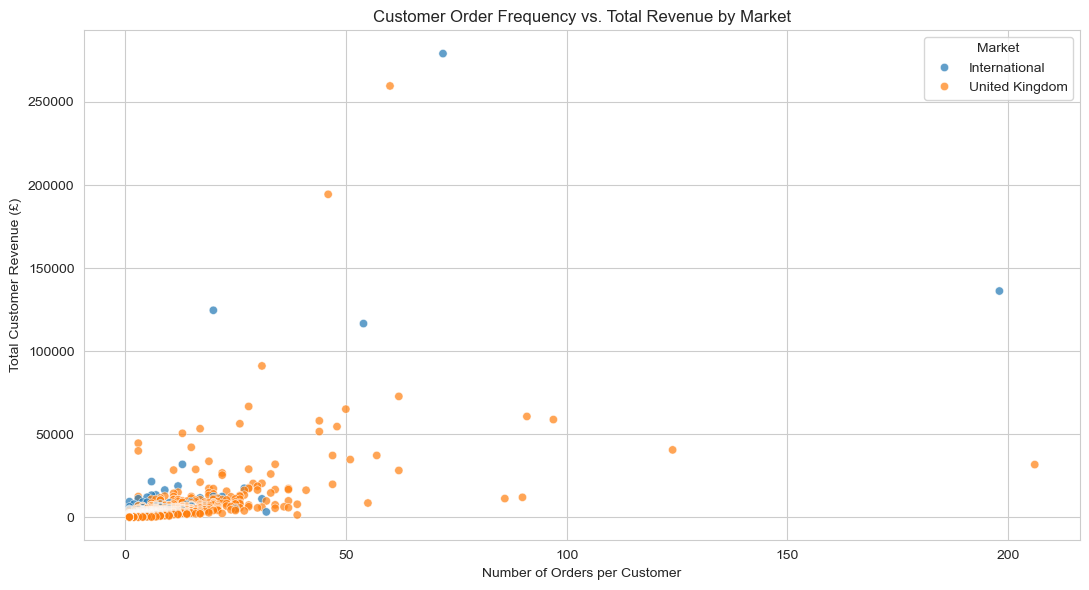

In [58]:
# Filter records with valid CustomerID for customer-level analysis
df_customers = df_clean[df_clean["CustomerID"].notnull()]

# Aggregate order count, total revenue, and primary market per customer
customer_summary = pd.DataFrame({
    "Orders": df_customers.groupby("CustomerID")["InvoiceNo"].nunique(),
    "Total_Revenue": df_customers.groupby("CustomerID")["Revenue"].sum(),
    "Market": df_customers.groupby("CustomerID")["Market"].first()
}).reset_index()

customer_summary["Avg_Order_Value"] = (customer_summary["Total_Revenue"] / customer_summary["Orders"]).round(2)
customer_summary = customer_summary.sort_values(by="Total_Revenue", ascending=False)

# Calculate customer concentration (Top 20% Pareto share) and repeat buyer rate
total_customers = len(customer_summary)
top_20_count = int(total_customers * 0.20)
top_20_share = (customer_summary.head(top_20_count)["Total_Revenue"].sum() / customer_summary["Total_Revenue"].sum()) * 100
repeat_rate = (customer_summary["Orders"] > 1).mean() * 100

print(f"Total identifiable customers:        {total_customers:,}")
print(f"Identified customer revenue:         £{customer_summary['Total_Revenue'].sum():,.2f}")
print(f"Repeat customers (> 1 order):        {repeat_rate:.2f}%")
print(f"Top 20% customers ({top_20_count:,}) revenue share: {top_20_share:.2f}%")

print("\nTop 10 Customers by Total Revenue:")
display(customer_summary.head(10))

# Scatter plot: Order Frequency vs Total Customer Revenue coloured by Market
plt.figure(figsize=(11, 6))
sns.scatterplot(x="Orders", y="Total_Revenue", hue="Market", data=customer_summary, alpha=0.7)
plt.title("Customer Order Frequency vs. Total Revenue by Market")
plt.xlabel("Number of Orders per Customer")
plt.ylabel("Total Customer Revenue (£)")
plt.tight_layout()
plt.show()

- **Objective:** To examine customer purchasing behaviour in terms of order frequency, total spending, repeat purchasing, and revenue concentration.
- **Why this plot:** A scatter plot displays the relationship between two numerical variables (number of orders and total customer revenue), while colouring by `Market` compares UK and international buyers. Aggregating by `CustomerID` also allows us to quantify repeat purchasing and revenue concentration.
- **Learning / Insights:** The cleaned dataset contains **4,333 identifiable customers** generating **£8,491,574.44** in cleaned sales revenue. Approximately **65.27%** of these customers placed more than one order during the period, indicating substantial **repeat purchasing** (note that this measures multiple orders within the dataset window rather than formal cohort retention). Revenue is concentrated among higher-spending buyers: the **top 20% of customers (866 buyers) account for 73.89%** of identified customer revenue, led by Customer **`14646`** (**£279,138.02**, 72 orders) and high-frequency buyer Customer **`14911`** (**198 orders**, £136,161.83). Transactions without a `CustomerID` (£1,510,680.04) are excluded here while remaining in overall sales totals, and `Market` reflects each customer's first recorded transaction.

## 6. Interactive Management Dashboard

### 6.1 Intended Audience, Structure, and Design Justification

- **Intended Audience:** Commercial and Operations Managers who need a clear, interactive overview of sales trends, product performance, regional markets, and order values without editing code.
- **Tool Choice (`Plotly Express` + `ipywidgets`):** Combining interactive visualisations from `Plotly Express` (Plotly Technologies Inc., n.d.) with interactive controls from `ipywidgets` (Project Jupyter, n.d.) enables hover tooltips, zoom, and responsive filtering directly inside Jupyter Notebook.
- **Interactive Controls & Usability:**
  1. **Country Selector (`Dropdown`):** View `All` markets, isolate `International Only` (preventing UK scale from compressing overseas bars), or drill down into a single country.
  2. **Metric Selector (`Dropdown`):** Switch Charts 1 to 3 between **Cleaned Sales Revenue (£)** and **Units Sold (Quantity)**, reflecting our EDA finding that revenue leaders and volume leaders differ.
  3. **Reporting Period (`SelectionRangeSlider`):** Select custom month windows (e.g., excluding the incomplete December 2011 period or isolating September to November 2011).
  4. **Minimum Order Value (`IntSlider`):** Filter invoices by total `InvoiceValue` (£0 to £2,000) to separate smaller orders from higher-value wholesale invoices.
  5. **Reset Filters (`Button`):** Restores all controls to their default values in one click.
- **Dashboard Layout:**
  - **Dynamic KPI Summary Table:** Displays Cleaned Sales Revenue (£), Unique Orders, Units Sold, Mean Order (£), Median Order (£), and Identifiable Customers for the active selection.
  - **Four Complementary Plotly Express Charts:** (1) Monthly Trend (`px.line`), (2) Top 10 Products (`px.bar`, horizontal, with Revenue/Quantity/Orders tooltips), (3) Top 10 Countries or Day-of-Week Breakdown for single-country selections (`px.bar`), and (4) Order Value Distribution up to the 95th percentile (`px.histogram`).

In [61]:
# Create interactive filter controls
country_options = ["All", "International Only"] + sorted(df_clean["Country"].unique().tolist())
months_list = sorted(df_clean["YearMonth"].unique().tolist())

country_dropdown = widgets.Dropdown(
    options=country_options,
    value="All",
    description="Country:",
    layout=widgets.Layout(width="270px")
)

metric_dropdown = widgets.Dropdown(
    options=[("Cleaned Sales Revenue (£)", "Revenue"), ("Units Sold (Quantity)", "Quantity")],
    value="Revenue",
    description="Metric:",
    layout=widgets.Layout(width="260px")
)

month_range_slider = widgets.SelectionRangeSlider(
    options=months_list,
    index=(0, len(months_list) - 1),
    description="Period:",
    continuous_update=False,
    layout=widgets.Layout(width="360px")
)

min_order_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=2000,
    step=50,
    description="Min Order (£):",
    continuous_update=False,
    layout=widgets.Layout(width="340px")
)

reset_button = widgets.Button(
    description="Reset Filters",
    button_style="warning",
    layout=widgets.Layout(width="130px")
)

# Reset all widgets back to their default values when clicked
def reset_filters(b):
    country_dropdown.value = "All"
    metric_dropdown.value = "Revenue"
    month_range_slider.index = (0, len(months_list) - 1)
    min_order_slider.value = 0

reset_button.on_click(reset_filters)

In [62]:
# Helper function to filter df_clean based on active widget selections
def filter_data(country, month_range, min_order_value):
    filtered = df_clean.copy()

    # Apply country or international-only filter
    if country == "International Only":
        filtered = filtered[filtered["Country"] != "United Kingdom"]
    elif country != "All":
        filtered = filtered[filtered["Country"] == country]

    # Apply selected month range
    start_month, end_month = month_range
    filtered = filtered[
        (filtered["YearMonth"] >= start_month) &
        (filtered["YearMonth"] <= end_month)
    ]

    # Apply minimum total invoice value filter
    filtered = filtered[filtered["InvoiceValue"] >= min_order_value]

    return filtered

In [63]:
# Main dashboard update function: KPI summary + 4 Plotly Express charts
def update_dashboard(country, metric, month_range, min_order_value):
    data = filter_data(country, month_range, min_order_value)
    start_month, end_month = month_range
    metric_label = "Cleaned Sales Revenue (£)" if metric == "Revenue" else "Units Sold (Quantity)"

    if data.empty:
        print("No records match your selected filters. Try widening the period or lowering Min Order (£).")
        return

    # Calculate and display dynamic executive KPIs
    order_vals = data.groupby("InvoiceNo", as_index=False)["Revenue"].sum()
    kpi_summary = pd.DataFrame({
        "Cleaned Sales Revenue (£)": [f"£{data['Revenue'].sum():,.2f}"],
        "Unique Orders": [f"{data['InvoiceNo'].nunique():,}"],
        "Units Sold": [f"{data['Quantity'].sum():,}"],
        "Mean Order (£)": [f"£{order_vals['Revenue'].mean():,.2f}"],
        "Median Order (£)": [f"£{order_vals['Revenue'].median():,.2f}"],
        "Identifiable Customers": [f"{data['CustomerID'].nunique():,}"]
    }, index=["Active Selection"])
    display(kpi_summary)

    # [1] Monthly Trend (Line Chart)
    monthly = data.groupby("YearMonth", as_index=False)[metric].sum()
    fig1 = px.line(
        monthly,
        x="YearMonth",
        y=metric,
        markers=True,
        template="plotly_white",
        title=f"Monthly {metric_label} Trend ({country}) ({start_month} to {end_month})",
        labels={"YearMonth": "Month", metric: metric_label}
    )
    fig1.update_layout(height=360)
    fig1.show()

    # [2] Top 10 Products (Horizontal Bar Chart with Revenue, Quantity, and Orders tooltips)
    prod_rev = data.groupby("Description")["Revenue"].sum()
    prod_qty = data.groupby("Description")["Quantity"].sum()
    prod_ord = data.groupby("Description")["InvoiceNo"].nunique()
    top_products = pd.DataFrame({
        "Revenue": prod_rev,
        "Quantity": prod_qty,
        "Orders": prod_ord
    }).reset_index()
    top_products = (
        top_products.sort_values(by=metric, ascending=False)
        .head(10)
        .sort_values(by=metric, ascending=True)
    )
    fig2 = px.bar(
        top_products,
        x=metric,
        y="Description",
        orientation="h",
        hover_data=["Revenue", "Quantity", "Orders"],
        template="plotly_white",
        color_discrete_sequence=["#264653"],
        title=f"Top 10 Products by {metric_label} ({country})",
        labels={metric: metric_label, "Description": "Product"}
    )
    fig2.update_layout(height=420)
    fig2.show()

    # [3] Top 10 Countries (multi-country view) OR Day-of-Week Breakdown (single-country view)
    if data["Country"].nunique() > 1:
        top_countries = (
            data.groupby("Country", as_index=False)[metric]
            .sum()
            .sort_values(by=metric, ascending=False)
            .head(10)
            .sort_values(by=metric, ascending=True)
        )
        fig3 = px.bar(
            top_countries,
            x=metric,
            y="Country",
            orientation="h",
            template="plotly_white",
            color_discrete_sequence=["#2a9d8f"],
            title=f"Top 10 Countries by {metric_label} ({country})",
            labels={metric: metric_label, "Country": "Country"}
        )
    else:
        weekday_metric = (
            data.groupby("DayOfWeek")[metric]
            .sum()
            .reindex(day_order, fill_value=0)
            .reset_index()
        )
        fig3 = px.bar(
            weekday_metric,
            x="DayOfWeek",
            y=metric,
            template="plotly_white",
            color_discrete_sequence=["#2a9d8f"],
            title=f"{metric_label} by Day of Week ({country})",
            labels={"DayOfWeek": "Day of Week", metric: metric_label}
        )
    fig3.update_layout(height=360)
    fig3.show()

    # [4] Order Value Distribution (Histogram up to 95th percentile of selection)
    p95_cutoff = order_vals["Revenue"].quantile(0.95)
    typical_vals = order_vals[order_vals["Revenue"] <= p95_cutoff]
    fig4 = px.histogram(
        typical_vals,
        x="Revenue",
        nbins=30,
        template="plotly_white",
        color_discrete_sequence=["#457b9d"],
        title=f"Order Value Distribution (Up to 95th Percentile: £{p95_cutoff:,.0f}) ({country})",
        labels={"Revenue": "Order Value (£)"}
    )
    fig4.update_layout(height=360, yaxis_title="Number of Orders")
    fig4.show()

In [64]:
# Organise controls into two clean horizontal rows and connect them to update_dashboard
row1 = widgets.HBox([country_dropdown, metric_dropdown, reset_button])
row2 = widgets.HBox([month_range_slider, min_order_slider])
controls = widgets.VBox([row1, row2])

out = widgets.interactive_output(
    update_dashboard,
    {
        "country": country_dropdown,
        "metric": metric_dropdown,
        "month_range": month_range_slider,
        "min_order_value": min_order_slider
    }
)

display(controls, out)

Output()

### 6.2 How Managers Can Use This Dashboard

The interactive controls support practical management queries across four common scenarios:

1. **Reviewing International Markets Without UK Scale Distortion:** Selecting **`International Only`** removes the UK (84.78% of revenue) so managers can focus on the Netherlands, EIRE, Germany, France, and Australia alongside their leading products and order values.
2. **Comparing Revenue Leaders vs. Volume Leaders:** Switching **`Metric`** between **`Cleaned Sales Revenue (£)`** and **`Units Sold (Quantity)`** updates Charts 1 to 3 immediately, while hovering over product bars displays exact Revenue, Quantity, and Order counts.
3. **Isolating Specific Periods:** Adjusting **`Period`** to **`2010-12` to `2011-11`** excludes the incomplete December 2011 window, while narrowing to **`2011-09` to `2011-11`** focuses on the pre-Christmas sales peak.
4. **Inspecting Higher-Value Wholesale Orders:** Increasing **`Min Order (£)`** (for example to **£500** or **£1,000**) filters for larger invoices, while clicking **`Reset Filters`** restores the full overview.

## 7. Business Insights & Recommendations

### 7.1 Synthesis of Key Business Findings

Combining the data quality audit, Exploratory Data Analysis (Section 5), and interactive dashboard (Section 6) addresses the five management questions defined in Section 1:

1. **Observed Pre-Christmas Sales Increase & Midday Trading Peaks:** Total cleaned product sales revenue reached **£10,002,254.48** across **19,771 unique orders**. Sales increased sharply from **September (+41.98% MoM)** and peaked in **November 2011 (£1,452,115.98; 2,751 orders)**. Operationally, **Thursday** led both cumulative revenue (**£2,131,755.60**) and average revenue per observed day (**£40,221.80** across 53 Thursdays), followed by **Tuesday** (£2,007,934.27; £38,614.12/day), with peak activity between **10:00 and 15:00** (highest at **12:00**). No transactions were recorded on **Saturday**, whereas **Sunday** accounted for **£798,311.50** (2,203 orders).
2. **Wide Range of Products with Distinct Revenue vs. Volume Leaders:** Across **4,007 unique products**, the top 10 products by revenue generate **8.03%** of total cleaned sales revenue. Notably, the product with the highest revenue (**`REGENCY CAKESTAND 3 TIER`**, £174,156.54) is different from the product with the highest unit volume (**`WORLD WAR 2 GLIDERS ASSTD DESIGNS`**, 54,951 units sold for £13,814.01).
3. **High Domestic Concentration with Focused European Opportunities:** The **United Kingdom** generates **84.78%** of cleaned sales revenue (£8,479,478.83), while **international markets** contribute **15.22%** (£1,522,775.65). Within international sales, the **top 10 countries account for 85.56%**, and the top four European markets (**Netherlands**, **EIRE**, **Germany**, and **France**) alone contribute **62.04%**.
4. **Right-Skewed Order Values:** The **overall mean order value (£505.91)** is substantially higher than the **median (£302.20)** because the top 5% of orders (**989 orders** above the 95th percentile of **£1,506.93**, up to **£52,940.94**) pull the average upward.
5. **High Repeat Purchasing & Customer Revenue Concentration:** Among **4,333 identifiable customers** (£8,491,574.44 in revenue), **65.27%** placed more than one order, and the **top 20% (866 customers) generated 73.89%** of identified customer revenue, led by Customer `14646` (£279,138.02) and high-frequency buyer Customer `14911` (198 orders).

---

### 7.2 Actionable Recommendations for Management

| Priority | Recommendation | Supporting Evidence |
| :--- | :--- | :--- |
| **1. Seasonal Stock & Capacity Planning** | Evaluate inventory levels, purchasing timelines, and warehouse capacity earlier in the year (by August) to prepare for the autumn/pre-Christmas demand surge. | Cleaned sales revenue increased by **41.98%** in September and peaked at **£1.45m** in November (2,751 orders). |
| **2. Key Account Management** | Develop a dedicated account management and relationship strategy for the top 20% of identifiable customers to support continued repeat purchasing. | **866 customers (20%)** generate **73.89%** of identified revenue, and **65.27%** of customers already place repeat orders. |
| **3. Focused European Expansion** | Prioritise commercial outreach, logistics review, and localised promotions in the **Netherlands, Ireland (EIRE), Germany, and France** rather than spreading resources evenly across all 37 overseas countries. | These four markets contribute approximately **62.04%** of international revenue (within the **85.56%** generated by the top 10), making them the strongest initial targets for focused expansion. |
| **4. Separate Revenue & Volume Strategies** | Manage pricing, stock replenishment, and promotions separately for products with the highest revenue (e.g., *Regency Cakestand 3 Tier*) versus high-volume products (e.g., *World War 2 Gliders*, *Jumbo Bags*). | The top revenue drivers and top unit-volume drivers are distinct products across the 4,007-item product range. |
| **5. Customer Data Capture & Order Auditing** | Investigate the causes of missing `CustomerID` values and improve customer identification data capture where appropriate; review cancellation workflows on unusually large invoices. | **25.15%** of cleaned rows (£1,510,680.04) lack a `CustomerID`, and two cancelled extreme invoices (`581483`, `541431`) totalled £245,653.20 before removal. |

## 8. Limitations & Conclusion

### 8.1 Key Limitations of the Analysis

Six important limitations of the dataset and methodology should be considered when interpreting these findings:

1. **Incomplete Final Month & Single Annual Cycle:** The dataset covers **1 December 2010 to 9 December 2011** (Chen, 2015). December 2011 contains only nine days of data, preventing full-month comparisons, and a single annual cycle is insufficient to prove recurring multi-year seasonality.
2. **Missing Customer Identifiers:** Missing `CustomerID` values represent **24.93%** of raw records (135,080 rows) and **25.15%** of cleaned records (**131,419 rows**, worth **£1,510,680.04** in cleaned sales revenue). While retained for total sales, product, and country totals, these records had to be excluded from customer-level concentration and repeat-purchasing calculations.
3. **No Cost or Profit Margin Data:** Only `UnitPrice` and `Quantity` are available; unit costs, shipping costs, and marketing expenses are not recorded. Therefore, this analysis measures **cleaned product sales revenue** rather than profitability.
4. **No Product Categories or Cancellation Reasons:** Products are described via free-text `Description` strings without structured categories, and cancelled invoices (`C` prefix) do not explain why cancellations occurred.
5. **Scope of Cleaning & Native Currency (`GBP / £`):** Removing cancelled invoices and administrative entries (`POST`, `DOT`, `M`, `C2`, `D`, etc.) isolates physical product sales, meaning shipping charges, discounts, and returns are outside the cleaned revenue total. All monetary figures preserve the dataset's native currency (**British Pounds Sterling, £**) as documented by Chen (2015) to avoid introducing arbitrary historical exchange-rate conversions.
6. **Absence of Saturday Records vs. Sunday Activity:** Although verified in `weekday_check`, the complete absence of Saturday transactions alongside 2,203 Sunday orders (£798,311.50) likely reflects internal order processing or invoicing schedules and should be verified with operations staff.

### 8.2 Conclusion

This project processed 541,909 raw online retail records through a transparent data quality assessment and cleaning workflow (retaining 522,570 valid product sales records, or 96.43%), engineered six business variables, built six static EDA visualisations, and delivered an interactive management dashboard using `Plotly Express` and `ipywidgets`. The analysis provides a structured basis for commercial exploration and supports further investigation into sales patterns, product performance, international markets, and customer purchasing behaviour.

## 9. References

- Chen, D. (2015) *Online Retail* [Dataset]. UCI Machine Learning Repository. Available at: [https://doi.org/10.24432/C5BW33](https://doi.org/10.24432/C5BW33) (Accessed: 26 November 2026).
- Chen, D., Sain, S.L. and Guo, K. (2012) 'Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining', *Journal of Database Marketing & Customer Strategy Management*, 19(3), pp. 197–208. Available at: [https://doi.org/10.1057/dbm.2012.17](https://doi.org/10.1057/dbm.2012.17).
- Harris, C.R., Millman, K.J., van der Walt, S.J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N.J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M.H., Brett, M., Haldane, A., del Río, J.F., Wiebe, M., Peterson, P., Gérard-Marchant, P., Sheppard, K., Reddy, T., Weckesser, W., Abbasi, H., Gohlke, C. and Oliphant, T.E. (2020) 'Array programming with NumPy', *Nature*, 585, pp. 357–362. Available at: [https://doi.org/10.1038/s41586-020-2649-2](https://doi.org/10.1038/s41586-020-2649-2).
- Hunter, J.D. (2007) 'Matplotlib: A 2D graphics environment', *Computing in Science & Engineering*, 9(3), pp. 90–95. Available at: [https://doi.org/10.1109/MCSE.2007.55](https://doi.org/10.1109/MCSE.2007.55).
- McKinney, W. (2010) 'Data structures for statistical computing in Python', *Proceedings of the 9th Python in Science Conference (SciPy 2010)*, pp. 56–61. Available at: [https://doi.org/10.25080/Majora-92bf1922-00a](https://doi.org/10.25080/Majora-92bf1922-00a).
- pandas development team (n.d.) *pandas documentation*. Available at: [https://pandas.pydata.org/docs/](https://pandas.pydata.org/docs/) (Accessed: 26 November 2026).
- Plotly Technologies Inc. (n.d.) *Plotly Open Source Graphing Library for Python*. Available at: [https://plotly.com/python/](https://plotly.com/python/) (Accessed: 26 November 2026).
- Project Jupyter (n.d.) *Jupyter Widgets documentation*. Available at: [https://ipywidgets.readthedocs.io/en/stable/](https://ipywidgets.readthedocs.io/en/stable/) (Accessed: 26 November 2026).
- Waskom, M.L. (2021) 'seaborn: statistical data visualization', *Journal of Open Source Software*, 6(60), p. 3021. Available at: [https://doi.org/10.21105/joss.03021](https://doi.org/10.21105/joss.03021).